# Sports Multimodal Data Preparation
This notebook loads the sports dataset, performs exploratory analysis, handles missing data, and preprocesses features to prepare them for building a logistic regression model.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

# Load the dataset
df = pd.read_csv('/content/sports_multimodal_data.csv')
display(df.head())

,heart_rate,emg_amplitude,skin_temp,gsr,respiratory_rate,spo2,bp_systolic,bp_diastolic,fatigue_index,acceleration,...,ambient_temp,humidity,heat_index,training_duration,previous_injury_history,rest_period,repetition_count,workload_intensity,acc_rms,injury_risk
0,74.967142,0.306745,33.154617,0.065939,17.977078,97.246223,117.657793,80.109155,54.831785,-0.718127,...,21.009398,24.789760,25.855921,62.680175,0,5.117926,31,4.754003,0.904436,0
1,68.617357,0.279614,33.035970,0.385663,11.316872,99.553279,124.918440,80.260665,59.224133,1.942509,...,18.718507,34.465135,28.447909,68.193399,0,6.045622,27,4.704938,1.184699,0
2,76.476885,0.134006,31.874060,0.339236,19.038077,98.053515,114.198061,88.185059,47.614986,0.567535,...,16.446042,77.616889,36.372307,89.855417,1,7.266212,36,5.687716,0.900029,0
3,85.230299,0.679033,32.550676,0.162285,14.772505,98.930086,124.997166,78.376715,36.039562,-2.097921,...,15.027612,34.447985,9.636166,69.332707,0,9.578920,27,6.770770,1.146620,0
4,67.658466,0.336259,33.003275,0.278293,14.371073,98.232013,117.869898,87.285347,55.066480,1.207819,...,25.860483,71.415446,28.544690,119.589317,0,6.276707,28,-0.172192,0.900294,0


In [2]:
# Explore data statistics and missing values
print("=== Dataset Info ===")
print(df.info())

print("\n=== Missing Values Summary ===")
print(df.isnull().sum())

print("\n=== Descriptive Statistics ===")
display(df.describe(include='all'))

=== Dataset Info ===
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5430 entries, 0 to 5429
Data columns (total 31 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   heart_rate               5430 non-null   float64
 1   emg_amplitude            5430 non-null   float64
 2   skin_temp                5430 non-null   float64
 3   gsr                      5430 non-null   float64
 4   respiratory_rate         5430 non-null   float64
 5   spo2                     5430 non-null   float64
 6   bp_systolic              5430 non-null   float64
 7   bp_diastolic             5430 non-null   float64
 8   fatigue_index            5430 non-null   float64
 9   acceleration             5430 non-null   float64
 10  angular_velocity         5430 non-null   float64
 11  body_orientation         5430 non-null   float64
 12  ground_reaction_force    5430 non-null   float64
 13  step_count               5430 non-null   int64  
 14  cad

,heart_rate,emg_amplitude,skin_temp,gsr,respiratory_rate,spo2,bp_systolic,bp_diastolic,fatigue_index,acceleration,...,ambient_temp,humidity,heat_index,training_duration,previous_injury_history,rest_period,repetition_count,workload_intensity,acc_rms,injury_risk
count,5430.000000,5430.000000,5430.000000,5430.000000,5430.000000,5430.000000,5430.000000,5430.000000,5430.000000,5430.000000,...,5430.000000,5430.000000,5430.000000,5430.000000,5430.000000,5430.000000,5430.000000,5430.000000,5430.000000,5430.000000
mean,70.020682,0.546094,33.008845,0.279551,15.951653,97.994149,119.775922,80.081034,50.156254,-0.009271,...,20.017661,50.286936,24.921006,89.971276,0.195948,8.009759,30.029282,6.007025,1.003417,0.049724
std,9.947648,0.257870,1.492605,0.129870,2.955197,0.999271,12.271519,7.864167,9.913094,1.006589,...,5.027518,17.263267,5.904732,30.023426,0.396966,1.994629,5.440587,1.976101,0.116746,0.217394
min,37.587327,0.100048,27.116400,0.050022,4.430874,94.467182,66.412754,52.415657,7.046090,-3.317318,...,2.675954,20.006399,1.004007,-11.864402,0.000000,1.292680,13.000000,-1.244942,0.805433,0.000000
25%,63.380668,0.326396,32.005512,0.167967,13.901322,97.308670,111.338549,74.667551,43.537513,-0.686116,...,16.657154,35.085108,21.013085,69.365770,0.000000,6.678934,26.000000,4.656978,0.899467,0.000000
50%,70.071208,0.542621,33.011805,0.281142,15.991920,97.999610,119.676402,80.167170,50.179794,-0.018379,...,20.100111,50.523963,24.862310,90.134615,0.000000,7.979147,30.000000,5.988525,1.005320,0.000000
75%,76.614017,0.767588,34.003980,0.391472,17.959894,98.680309,128.166929,85.375101,56.922337,0.666043,...,23.338922,65.334940,28.857975,110.397499,0.000000,9.366123,34.000000,7.345809,1.105180,0.000000
max,109.262377,0.999706,38.143366,0.499955,26.834050,101.691625,164.734000,106.367236,85.365317,3.401876,...,38.831168,79.991127,44.991934,198.523867,1.000000,14.490244,51.000000,13.953736,1.207799,1.000000


Now we will build a preprocessing pipeline. Based on typical preprocessing requirements for logistic regression, we will scale numerical features and one-hot encode categorical features. (Adjustments can be made depending on the columns identified in the exploration step).

In [3]:
# Identify feature types (excluding potential targets or unique identifiers)
# Since we haven't seen the exact columns yet, we write a general dynamic preparation routine
numeric_features = df.select_dtypes(include=['int64', 'float64']).columns.tolist()
categorical_features = df.select_dtypes(include=['object', 'category']).columns.tolist()

print("Numerical features:", numeric_features)
print("Categorical features:", categorical_features)

# Note: Please make sure to identify which column is your target variable (Y)
# For preparation, we'll define a standard pipeline layout which can be applied once the target is selected.

Numerical features: ['heart_rate', 'emg_amplitude', 'skin_temp', 'gsr', 'respiratory_rate', 'spo2', 'bp_systolic', 'bp_diastolic', 'fatigue_index', 'acceleration', 'angular_velocity', 'body_orientation', 'ground_reaction_force', 'step_count', 'cadence', 'jump_height', 'range_of_motion', 'impact_force', 'gait_symmetry', 'speed', 'altitude', 'ambient_temp', 'humidity', 'heat_index', 'training_duration', 'previous_injury_history', 'rest_period', 'repetition_count', 'workload_intensity', 'acc_rms', 'injury_risk']
Categorical features: []


### Train-Test Split and Model Training
We will define the features ($X$) and the target ($y$, which is `injury_risk`). Then we will scale our numerical columns and train the Logistic Regression model.

In [4]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, classification_report

# Define Features (X) and Target (y)
X = df.drop(columns=['injury_risk'])
y = df['injury_risk']

# Split into training and testing sets (80% train, 20% test)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

# Scale the features (Logistic Regression is sensitive to feature scales)
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print(f"Training set shape: {X_train_scaled.shape}")
print(f"Testing set shape: {X_test_scaled.shape}")

Training set shape: (4344, 30)
Testing set shape: (1086, 30)


In [5]:
from sklearn.linear_model import LogisticRegression

# Initialize and train the Logistic Regression Model
model = LogisticRegression(max_iter=1000, random_state=42)
model.fit(X_train_scaled, y_train)

# Make predictions on test data
y_pred = model.predict(X_test_scaled)

# Calculate evaluation metrics
accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred)
recall = recall_score(y_test, y_pred)
f1 = f1_score(y_test, y_pred)

# Display Results
print("=== Logistic Regression Metrics ===")
print(f"Accuracy:  {accuracy:.4f}")
print(f"Precision: {precision:.4f}")
print(f"Recall:    {recall:.4f}")
print(f"F1 Score:  {f1:.4f}")
print("\nClassification Report:")
print(classification_report(y_test, y_pred))

=== Logistic Regression Metrics ===
Accuracy:  0.9586
Precision: 0.6552
Recall:    0.3519
F1 Score:  0.4578

Classification Report:
              precision    recall  f1-score   support

           0       0.97      0.99      0.98      1032
           1       0.66      0.35      0.46        54

    accuracy                           0.96      1086
   macro avg       0.81      0.67      0.72      1086
weighted avg       0.95      0.96      0.95      1086



### Evaluating Metrics Across Different Thresholds
Since the default decision threshold is 0.5, we can analyze how changing this threshold impacts our performance metrics (Accuracy, Precision, Recall, and F1-score).

In [10]:
# Get predicted probabilities for the positive class (injury_risk = 1)
y_probs = model.predict_proba(X_test_scaled)[:, 1]

# Define a range of thresholds to evaluate
thresholds = np.arange(0.1, 1.0, 0.1)

# Lists to store metrics
accuracies = []
precisions = []
recalls = []
f1_scores = []

for t in thresholds:
    # Apply threshold
    preds = (y_probs >= t).astype(int)

    # Calculate metrics
    accuracies.append(accuracy_score(y_test, preds))
    precisions.append(precision_score(y_test, preds, zero_division=0))
    recalls.append(recall_score(y_test, preds, zero_division=0))
    f1_scores.append(f1_score(y_test, preds, zero_division=0))

# Create a DataFrame to display the metrics side-by-side
metrics_df = pd.DataFrame({
    'Threshold': thresholds,
    'Accuracy': accuracies,
    'Precision': precisions,
    'Recall': recalls,
    'F1-Score': f1_scores
})

display(metrics_df.round(4))

,Threshold,Accuracy,Precision,Recall,F1-Score
0,0.1,0.9070,0.3285,0.8333,0.4712
1,0.2,0.9355,0.4070,0.6481,0.5000
2,0.3,0.9466,0.4714,0.6111,0.5323
3,0.4,0.9512,0.5106,0.4444,0.4752
4,0.5,0.9586,0.6552,0.3519,0.4578
5,0.6,0.9604,0.7200,0.3333,0.4557
6,0.7,0.9595,0.8571,0.2222,0.3529
7,0.8,0.9576,1.0000,0.1481,0.2581
8,0.9,0.9530,1.0000,0.0556,0.1053


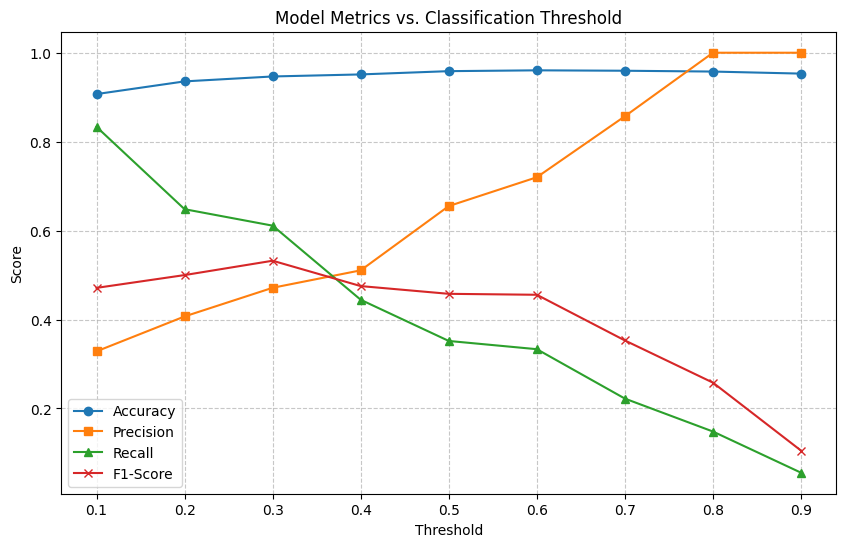

In [7]:
# Plot the metrics across different thresholds
plt.figure(figsize=(10, 6))
plt.plot(thresholds, accuracies, label='Accuracy', marker='o')
plt.plot(thresholds, precisions, label='Precision', marker='s')
plt.plot(thresholds, recalls, label='Recall', marker='^')
plt.plot(thresholds, f1_scores, label='F1-Score', marker='x')

plt.title('Model Metrics vs. Classification Threshold')
plt.xlabel('Threshold')
plt.ylabel('Score')
plt.legend()
plt.grid(True, linestyle='--', alpha=0.7)
plt.show()

### Decision Tree Model Evaluation
We will evaluate a Decision Tree classifier on the same train/test split. We will tune and print the performance metrics (Accuracy, Precision, Recall, and F1-score) for different values of tree depth (`max_depth`) and maximum leaves (`max_leaf_nodes`).

In [8]:
from sklearn.tree import DecisionTreeClassifier

# Define hyperparameter ranges to explore
depths = [3, 5, 7, 10, None]
max_leaves = [5, 10, 20, 50, None]

results = []

for depth in depths:
    for leaves in max_leaves:
        # Initialize and train the Decision Tree
        dt_model = DecisionTreeClassifier(
            max_depth=depth,
            max_leaf_nodes=leaves,
            random_state=42,
            class_weight='balanced'  # Balancing the classes as we have an imbalanced dataset
        )
        dt_model.fit(X_train_scaled, y_train)

        # Predict on test set
        preds = dt_model.predict(X_test_scaled)

        # Calculate metrics
        acc = accuracy_score(y_test, preds)
        prec = precision_score(y_test, preds, zero_division=0)
        rec = recall_score(y_test, preds, zero_division=0)
        f1 = f1_score(y_test, preds, zero_division=0)

        results.append({
            'Max Depth': 'Unlimited' if depth is None else depth,
            'Max Leaves': 'Unlimited' if leaves is None else leaves,
            'Accuracy': acc,
            'Precision': prec,
            'Recall': rec,
            'F1-Score': f1
        })

# Convert results to DataFrame and display
dt_results_df = pd.DataFrame(results)
display(dt_results_df.round(4))

,Max Depth,Max Leaves,Accuracy,Precision,Recall,F1-Score
0,3,5,0.9963,1.00,0.9259,0.9615
1,3,10,0.9963,1.00,0.9259,0.9615
2,3,20,0.9963,1.00,0.9259,0.9615
3,3,50,0.9963,1.00,0.9259,0.9615
4,3,Unlimited,0.9963,1.00,0.9259,0.9615
5,5,5,0.9807,0.72,1.0000,0.8372
6,5,10,1.0000,1.00,1.0000,1.0000
7,5,20,1.0000,1.00,1.0000,1.0000
8,5,50,1.0000,1.00,1.0000,1.0000
9,5,Unlimited,1.0000,1.00,1.0000,1.0000


### Neural Network (MLP) Model Evaluation
We will evaluate standard Multi-Layer Perceptron (MLP) architectures on the same scaled train/test split. We will test different network depths and widths (number of layers and neurons per layer) and print out the respective evaluation metrics.

In [9]:
from sklearn.neural_network import MLPClassifier

# Define different neural network architectures to test
# Each tuple represents the (neurons_in_layer_1, neurons_in_layer_2, ...)
architectures = {
    "1 Layer (16 neurons)": (16,),
    "1 Layer (64 neurons)": (64,),
    "2 Layers (32, 16 neurons)": (32, 16),
    "2 Layers (64, 32 neurons)": (64, 32),
    "3 Layers (64, 32, 16 neurons)": (64, 32, 16)
}

nn_results = []

for name, config in architectures.items():
    # Initialize and train the MLP Classifier
    mlp = MLPClassifier(
        hidden_layer_sizes=config,
        max_iter=500,
        random_state=42,
        early_stopping=True
    )
    mlp.fit(X_train_scaled, y_train)

    # Predict on test set
    preds = mlp.predict(X_test_scaled)

    # Calculate evaluation metrics
    acc = accuracy_score(y_test, preds)
    prec = precision_score(y_test, preds, zero_division=0)
    rec = recall_score(y_test, preds, zero_division=0)
    f1 = f1_score(y_test, preds, zero_division=0)

    nn_results.append({
        'Architecture': name,
        'Hidden Layers Layout': str(config),
        'Accuracy': acc,
        'Precision': prec,
        'Recall': rec,
        'F1-Score': f1
    })

# Convert results to DataFrame and display
nn_results_df = pd.DataFrame(nn_results)
display(nn_results_df.round(4))

,Architecture,Hidden Layers Layout,Accuracy,Precision,Recall,F1-Score
0,1 Layer (16 neurons),"(16,)",0.9503,0.5000,0.0741,0.1290
1,1 Layer (64 neurons),"(64,)",0.9521,0.6250,0.0926,0.1613
2,"2 Layers (32, 16 neurons)","(32, 16)",0.9503,0.0000,0.0000,0.0000
3,"2 Layers (64, 32 neurons)","(64, 32)",0.9521,0.5312,0.3148,0.3953
4,"3 Layers (64, 32, 16 neurons)","(64, 32, 16)",0.9448,0.4118,0.2593,0.3182
